# Constructing modules without a filtration

A finite diagram of vector spaces and maps is already a meaningful input. We can give TamerOp that algebra directly, without first constructing a point cloud or filtered complex. The finite module is then ready for the same stalk, rank and categorical operations used after encoding geometric data.

This guide assumes matrix multiplication and a little familiarity with [spaces and maps](../spaces_and_maps.md). We will construct a diamond over the rationals, deliberately break one commuting relation, and repair it before exporting an ordinary module. A finite indicator presentation provides a second way to specify the input. See the [editor reference](../src/reference/visual_sessions.md#author-a-finite-module-or-presentation) for the full input contract.

In [1]:
using TamerOp
using CairoMakie
const OP = TamerOp
const A = TamerOp.Advanced

TamerOp.Advanced

## Enter the finite diagram

The four vertices have relations $1<2<4$ and $1<3<4$. Vertices 2 and 3 are incomparable. Every stalk initially has dimension one, and each cover map is the identity. Thus both routes from 1 to 4 multiply to 1.

`order[i,j]` records $i\leq j$, including the diagonal and transitive relation $1\leq4$. Enter matrices only on covers: composite maps are consequences of those entries.

In [2]:
order = Bool[1 1 1 1;
             0 1 0 1;
             0 0 1 1;
             0 0 0 1]
cover_maps = Dict((1, 2) => [1;;], (1, 3) => [1;;],
                  (2, 4) => [1;;], (3, 4) => [1;;])

Dict{Tuple{Int64, Int64}, Matrix{Int64}} with 4 entries:
  (2, 4) => [1;;]
  (1, 2) => [1;;]
  (1, 3) => [1;;]
  (3, 4) => [1;;]

In [3]:
editor = OP.module_editor(; order, dimensions=[1, 1, 1, 1], maps=cover_maps)
@assert A.check_module_editor(editor).valid
OP.describe(editor)

(kind = :module_editor, valid = true, input_kind = :module, field = TamerOp.CoreModules.CoeffFields.QQField(), selection = (vertex = 1, edge = (1, 2), revision = 0), revision = 0, closed = false, updating = false, undo_count = 0, redo_count = 0, history_limit = 32, listener_count = 0, listener_errors = (), limits = (max_vertices = 32, max_dimension = 32, max_entries = 20000))

The editor holds an independent input draft. Its graph is a schematic Hasse diagram: horizontal distances have no geometric meaning. The selected matrix uses rows for the target and columns for the source.

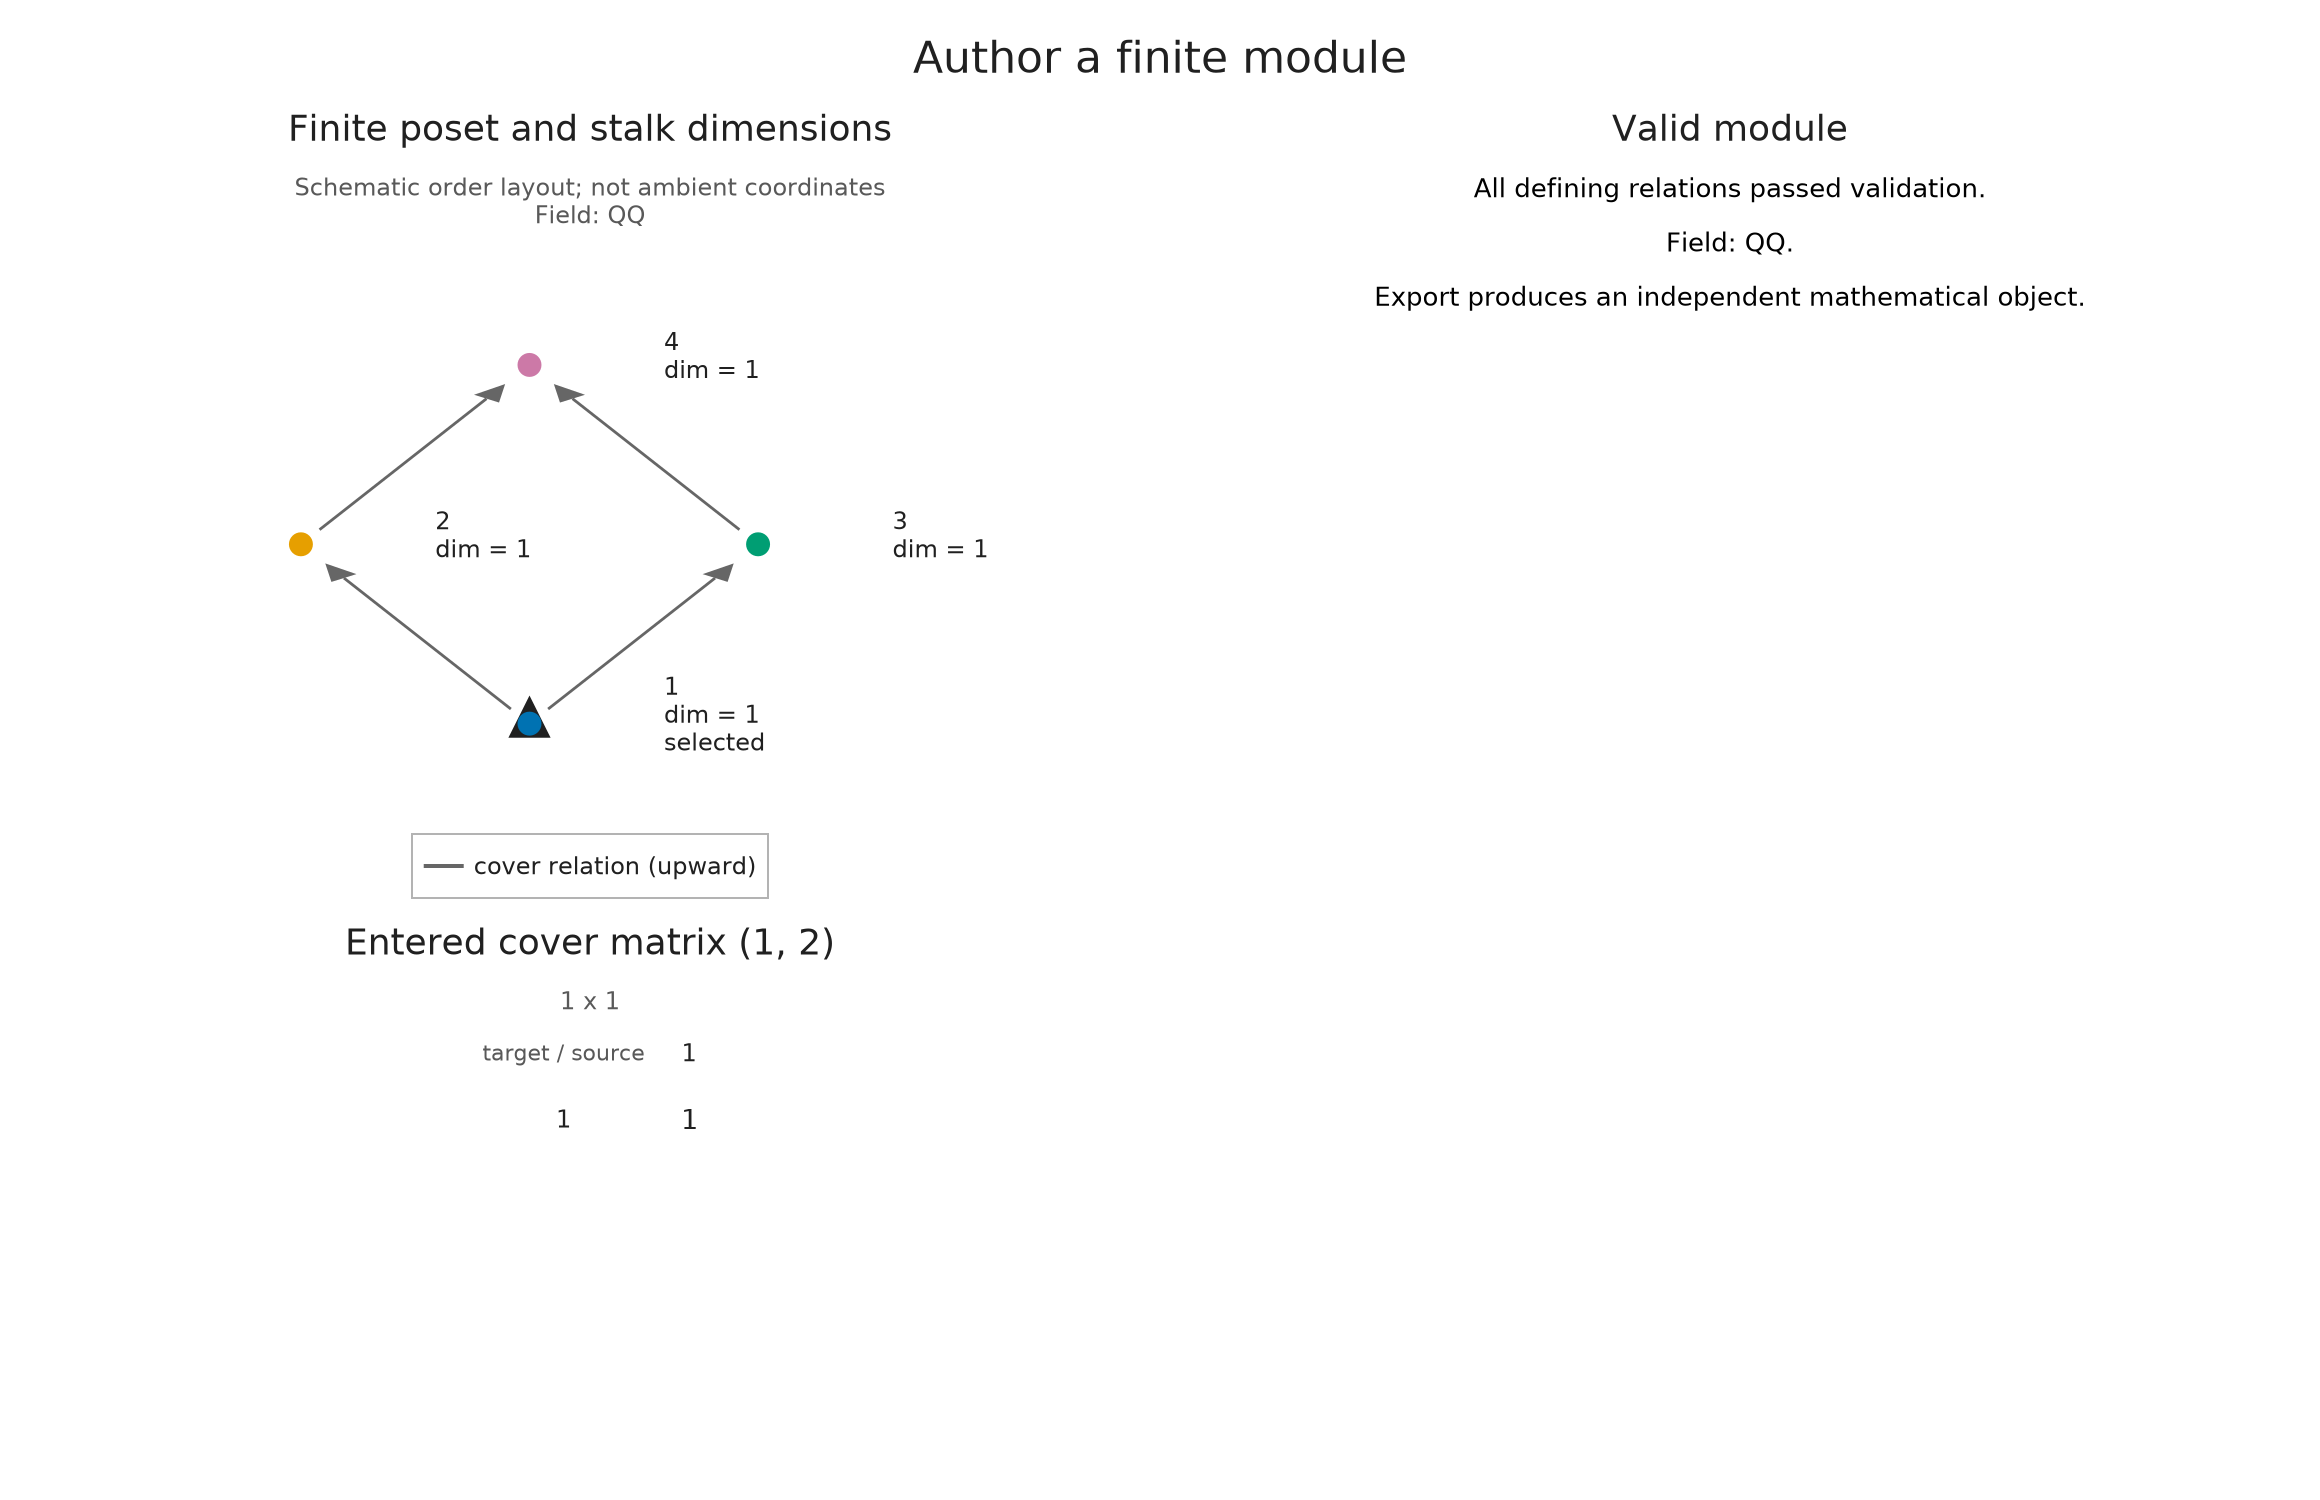

In [4]:
OP.visualize(A.inspection_snapshot(editor))

## Make the two routes disagree

Change only the map from 3 to 4 to multiplication by 2. Predict the composites before running the next cells. Does having a legal matrix on every arrow suffice to define a functor from the poset?

In [5]:
OP.edit_module!(editor; map=((3, 4), [2;;]))
report = A.check_module_editor(editor)
@assert !report.valid
report.issues

1-element Vector{String}:
 "Paths 1 -> 2 -> 4 and 1 -> 3 -> 4 have different composites."

In [6]:
witness = report.witness
@assert witness.first_path == [1, 2, 4]
@assert witness.second_path == [1, 3, 4]
@assert witness.first_composite == [1;;]
@assert witness.second_composite == [2;;]
(first=witness.first_composite, second=witness.second_composite)

(first = Rational{BigInt}[1;;], second = Rational{BigInt}[2;;])

The matrices have legal shapes, but their composites are unequal. The draft remains visible so we can diagnose it. `editor_object(editor)` and code export reject it: there is no single structure map from 1 to 4 compatible with these four arrows.

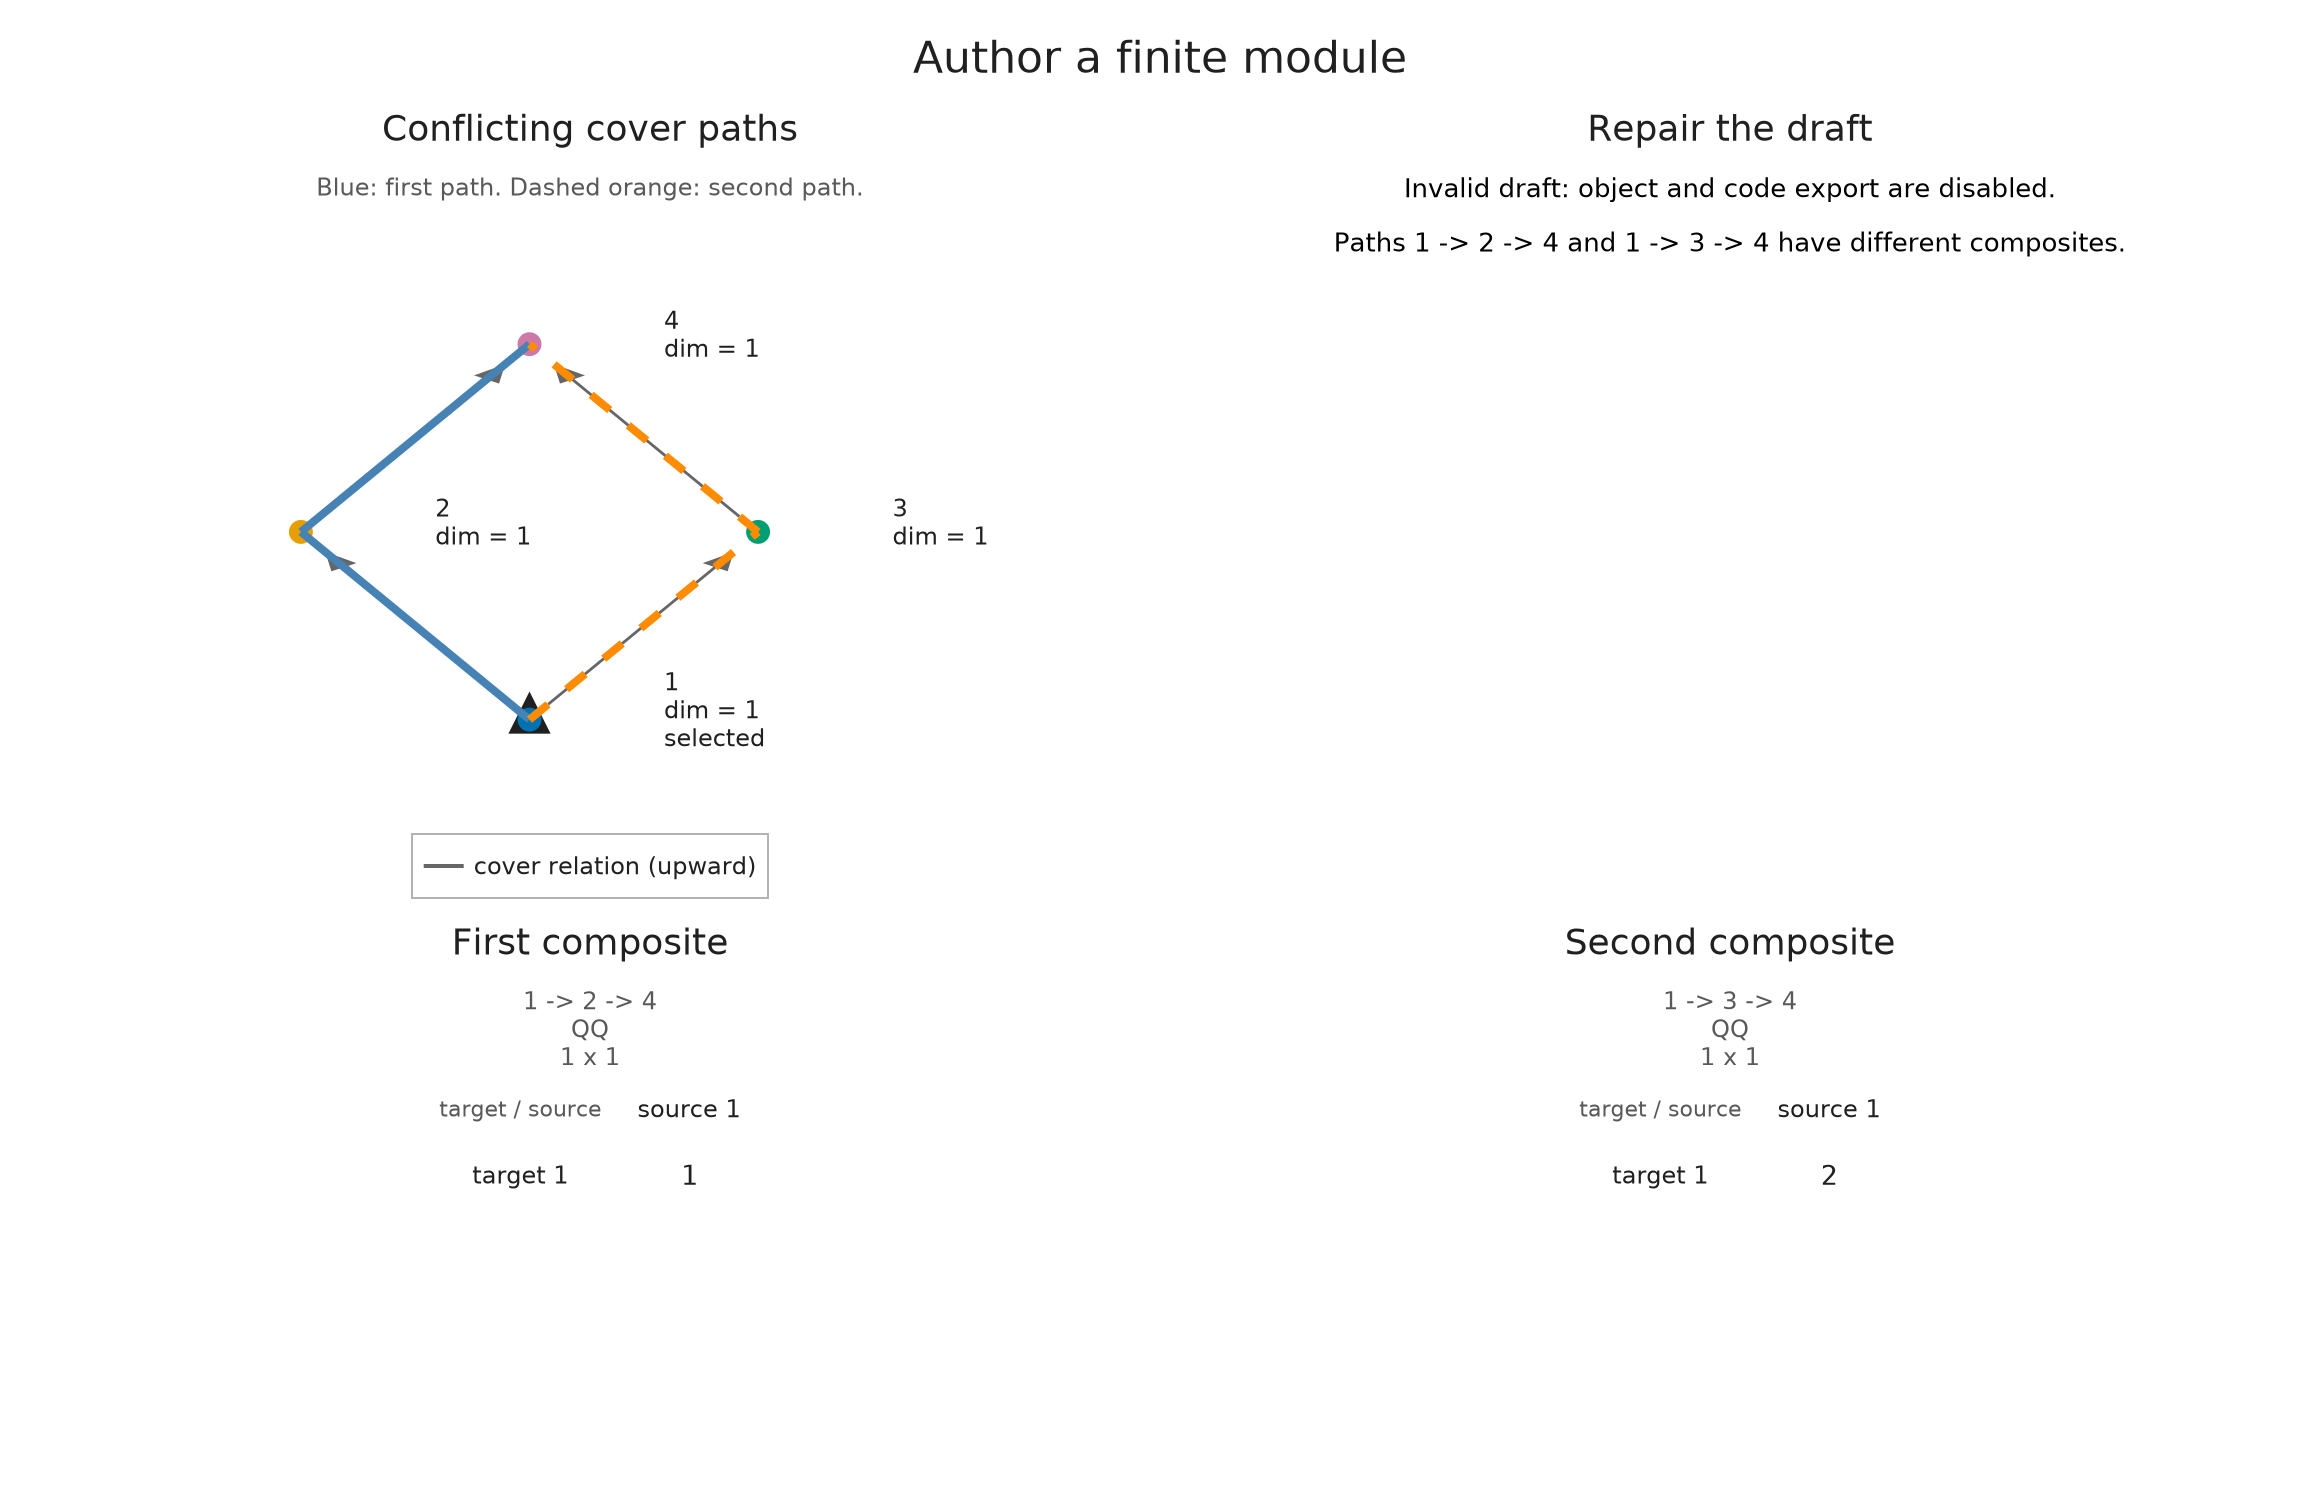

In [7]:
OP.visualize(A.inspection_snapshot(editor))

## Repair, then change the target space

Undo restores the previous draft. Next let the terminal stalk have dimension two. We supply both incoming column matrices explicitly. The editor does not pad or resize matrices when a dimension changes.

In [8]:
A.undo_module_edit!(editor)
@assert A.check_module_editor(editor).valid
larger_maps = copy(cover_maps)
larger_maps[(2, 4)] = reshape([1, 2], 2, 1)
larger_maps[(3, 4)] = reshape([1, 2], 2, 1)
OP.edit_module!(editor; dimensions=[1, 1, 1, 2], maps=larger_maps)
A.select_inspection!(editor; vertex=4, edge=(3, 4))

ModuleEditorSession(module, valid=true, revision=4, closed=false)

In [9]:
M = OP.editor_object(editor)
@assert OP.dimensions(M).stalks == [1, 1, 1, 2]
@assert A.structure_map(M; source=1, target=4) == reshape([1, 2], 2, 1)
A.structure_map(M; source=1, target=4)

2×1 Matrix{Rational{BigInt}}:
 1
 2

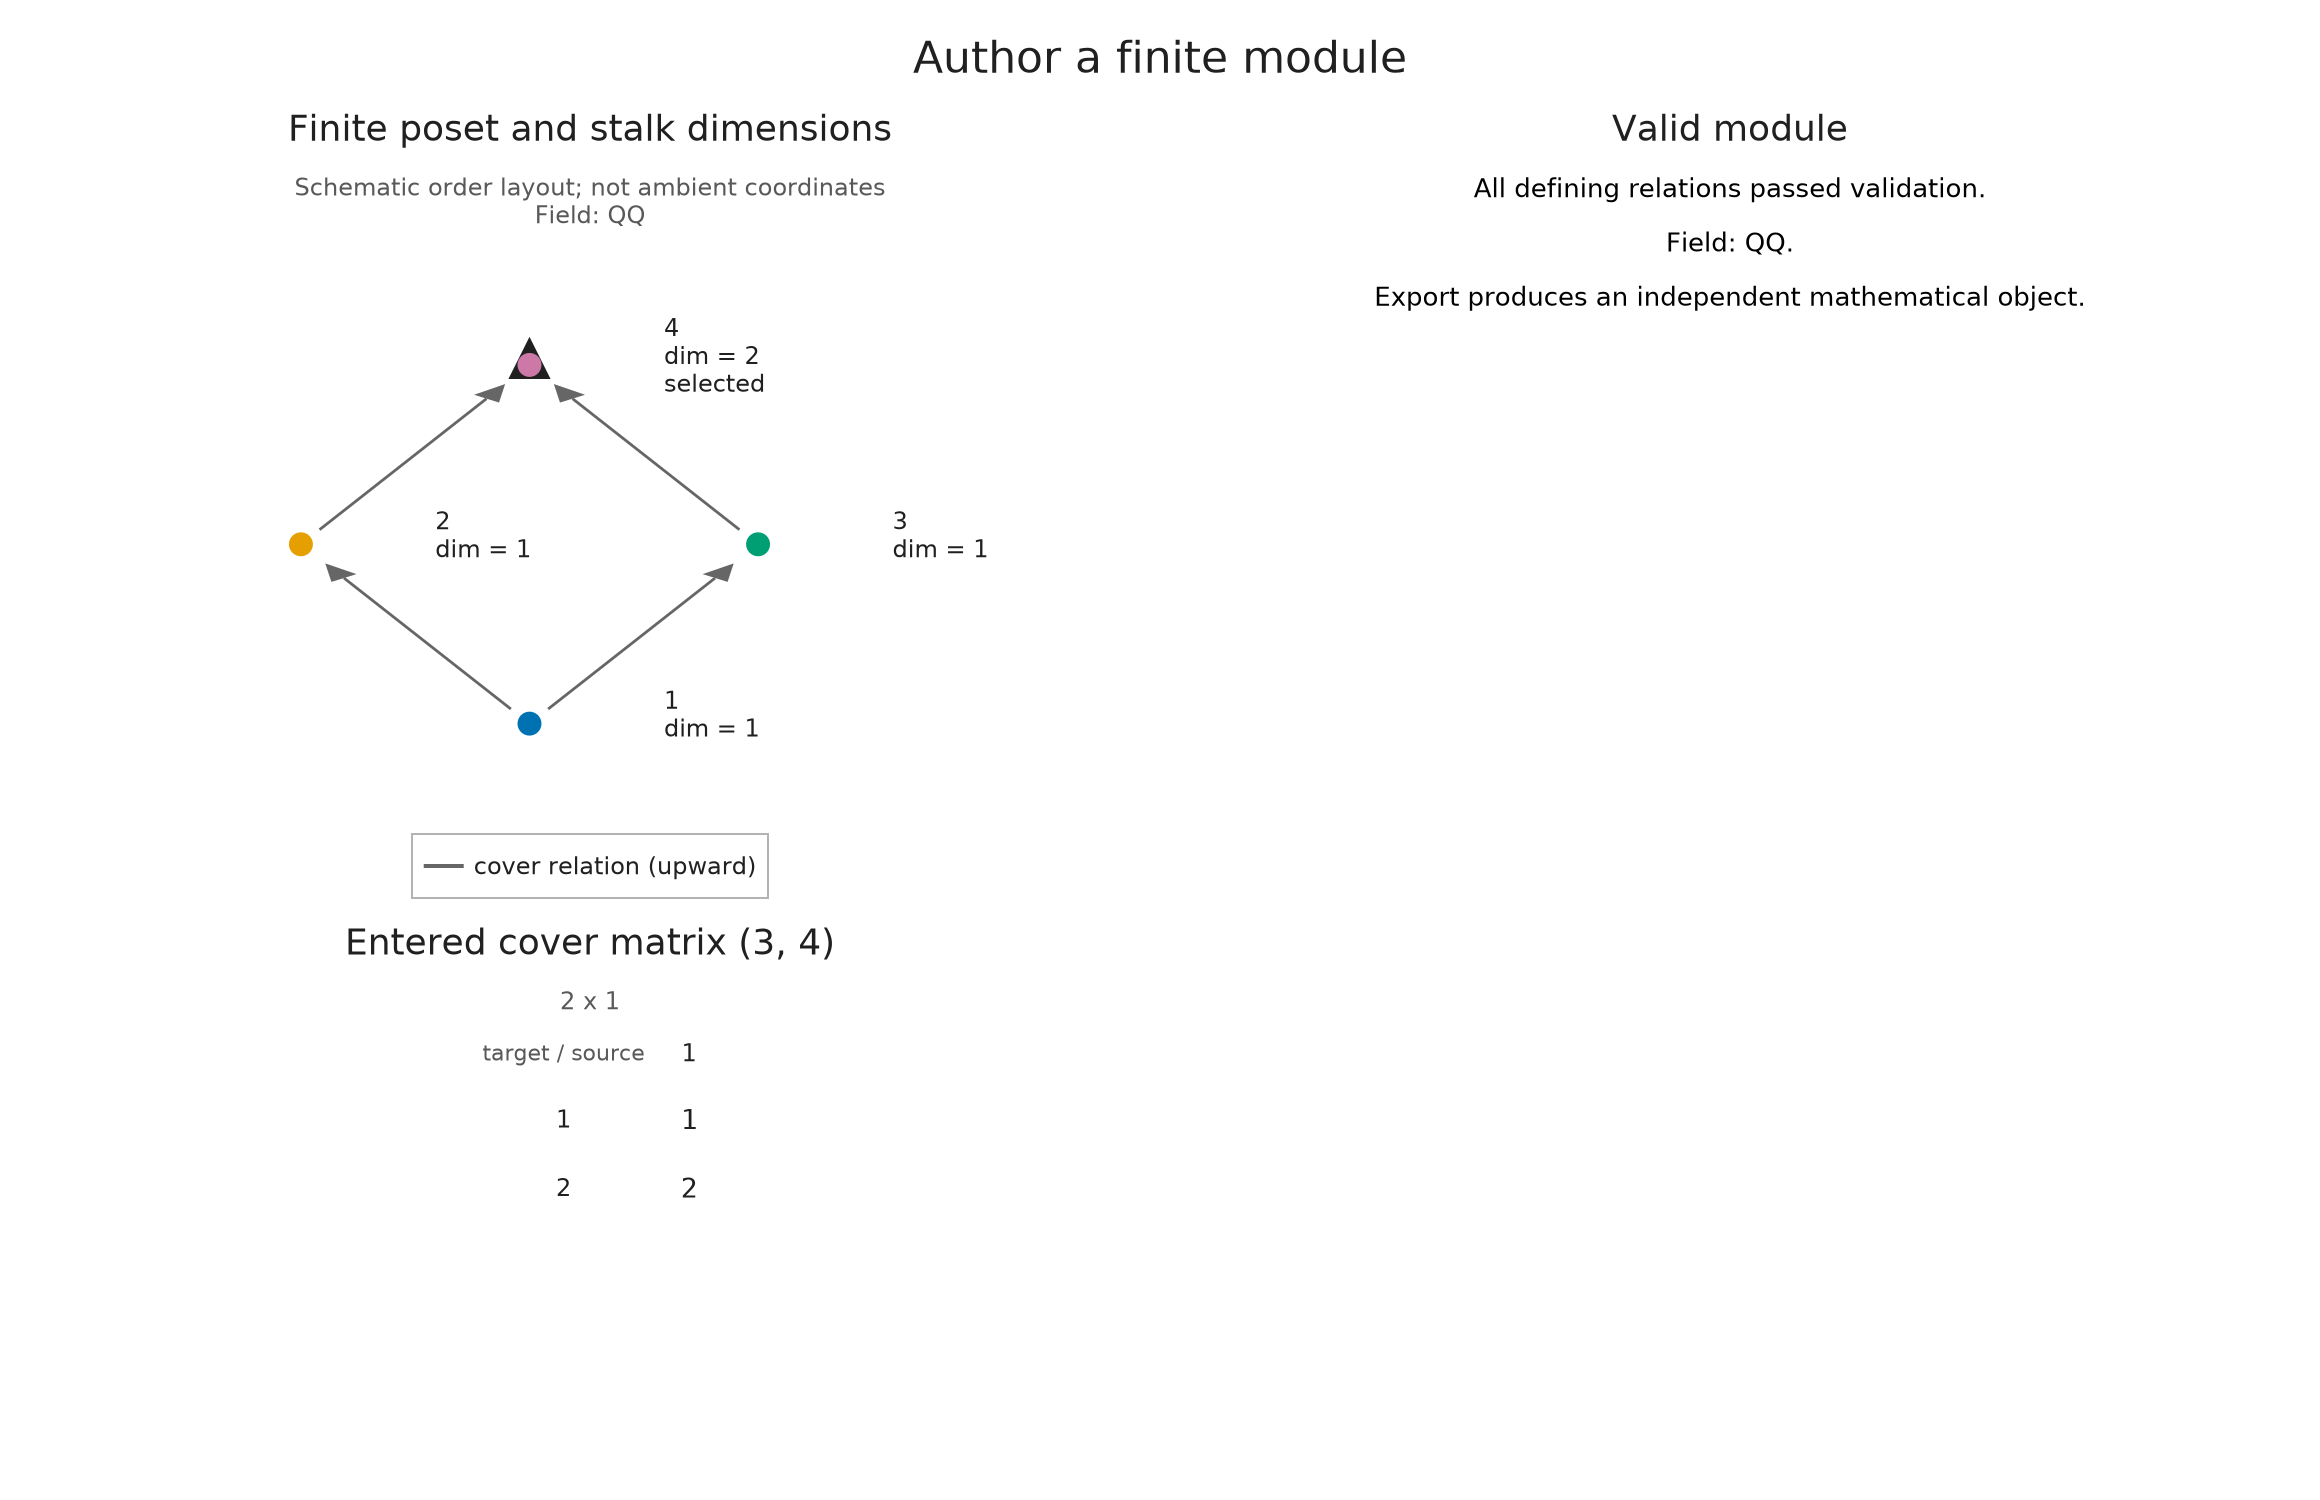

In [10]:
OP.visualize(A.inspection_snapshot(editor))

`M` is an ordinary finite-poset module, independent of subsequent edits. It can enter [maps and categorical constructions](../src/reference/modules.md) directly. To interpret this finite diagram over a continuous or lattice parameter space, we would additionally need an explicit classifier; the editor does not infer one from the drawing.

## Edit through a live viewer

With WGLMakie loaded, `OP.visualize(editor; backend=:wglmakie)` opens the same draft in a live editor. The source/target and matrix controls are keyboard-accessible; order and indicator supports have their own expandable tables. Apply commits a draft edit. Undo and redo operate on those edits, while changing the selected vertex only navigates.

The **Generate Julia code** control is enabled only for valid drafts. **Prepare saved draft** can retain an invalid example for later diagnosis. Live controls require Julia; a portable saved figure switches only among captured states. Standalone browser behavior and notebook host qualification are separate in the [support matrix](../visualization_support.md).

## An indicator presentation is another input

On the chain $1<2<3$, take the upset $\{2,3\}$ and downset $\{1,2\}$ with coefficient 1. Their image is supported only at vertex 2. Here the editable matrix is a fringe coefficient matrix, not a list of cover maps. The image construction supplies the represented module.

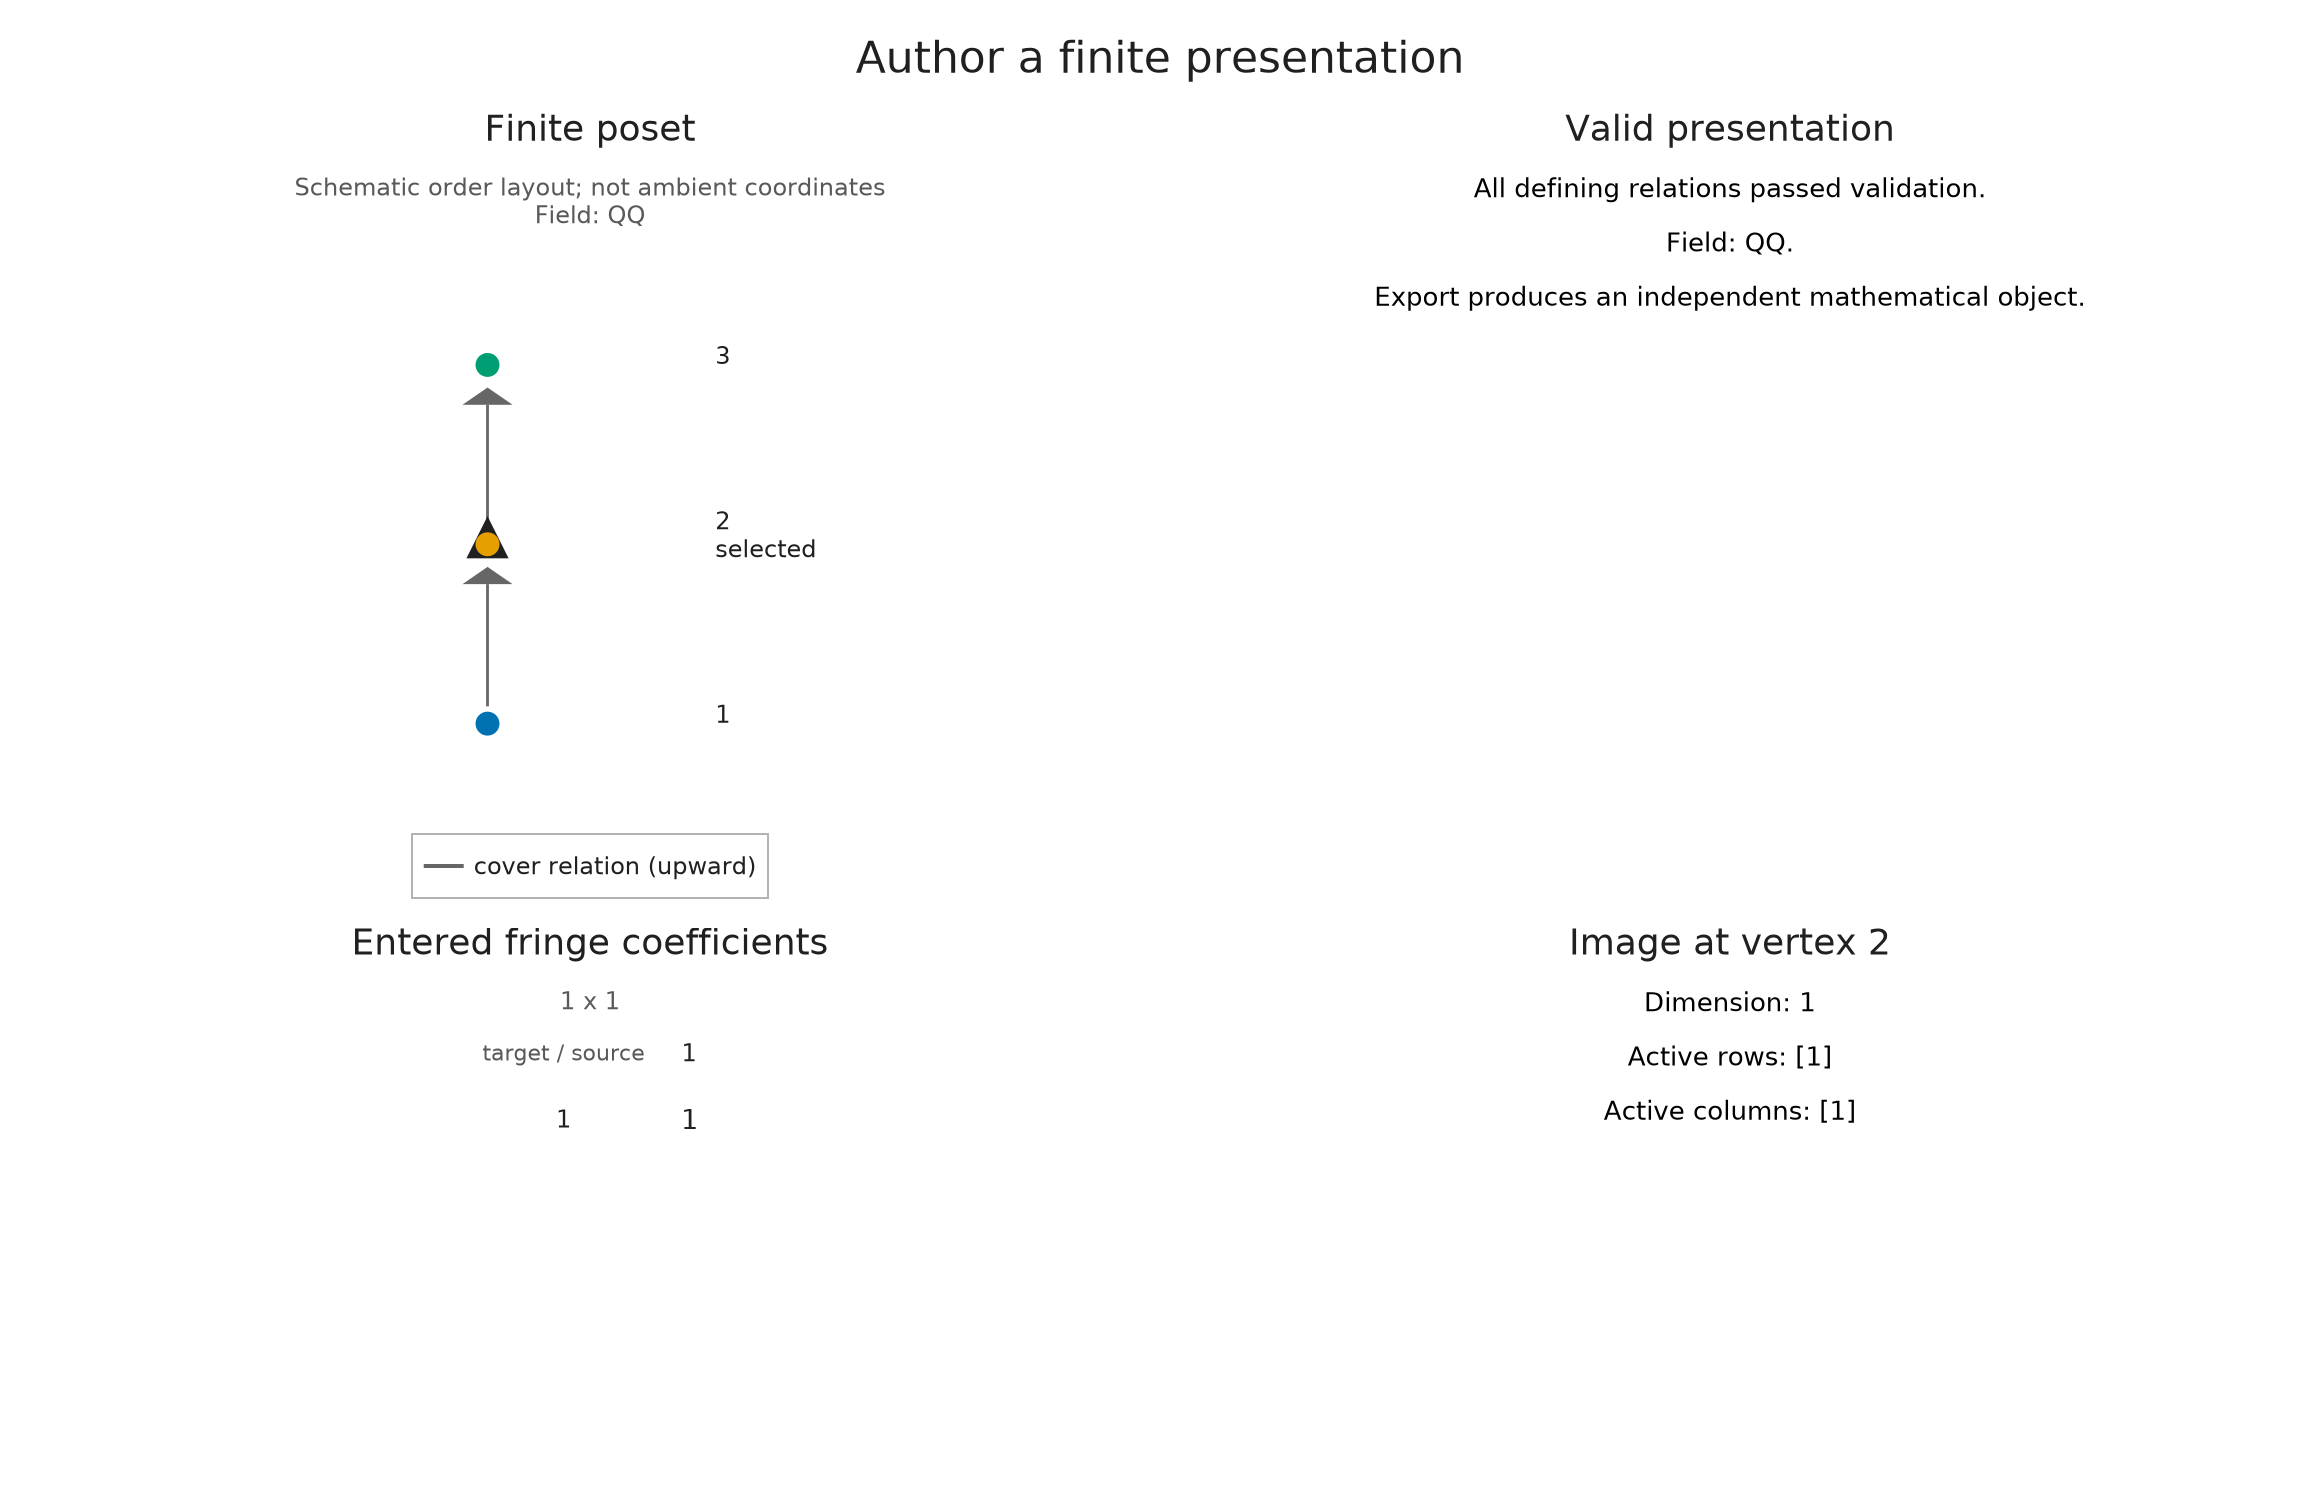

In [11]:
presentation = OP.module_editor(; order=Bool[1 1 1; 0 1 1; 0 0 1],
    upsets=[[2, 3]], downsets=[[1, 2]], matrix=[1;;])
A.select_inspection!(presentation; vertex=2)
H = OP.editor_object(presentation)
@assert OP.dimensions(H).fibers == [0, 1, 0]
OP.visualize(A.inspection_snapshot(presentation))

Changing the active coefficient to zero keeps both supports and gives a zero-dimensional image. A zero coefficient is different from deleting a support. An entered support that is not upward/downward closed is invalid; the editor does not complete it silently.

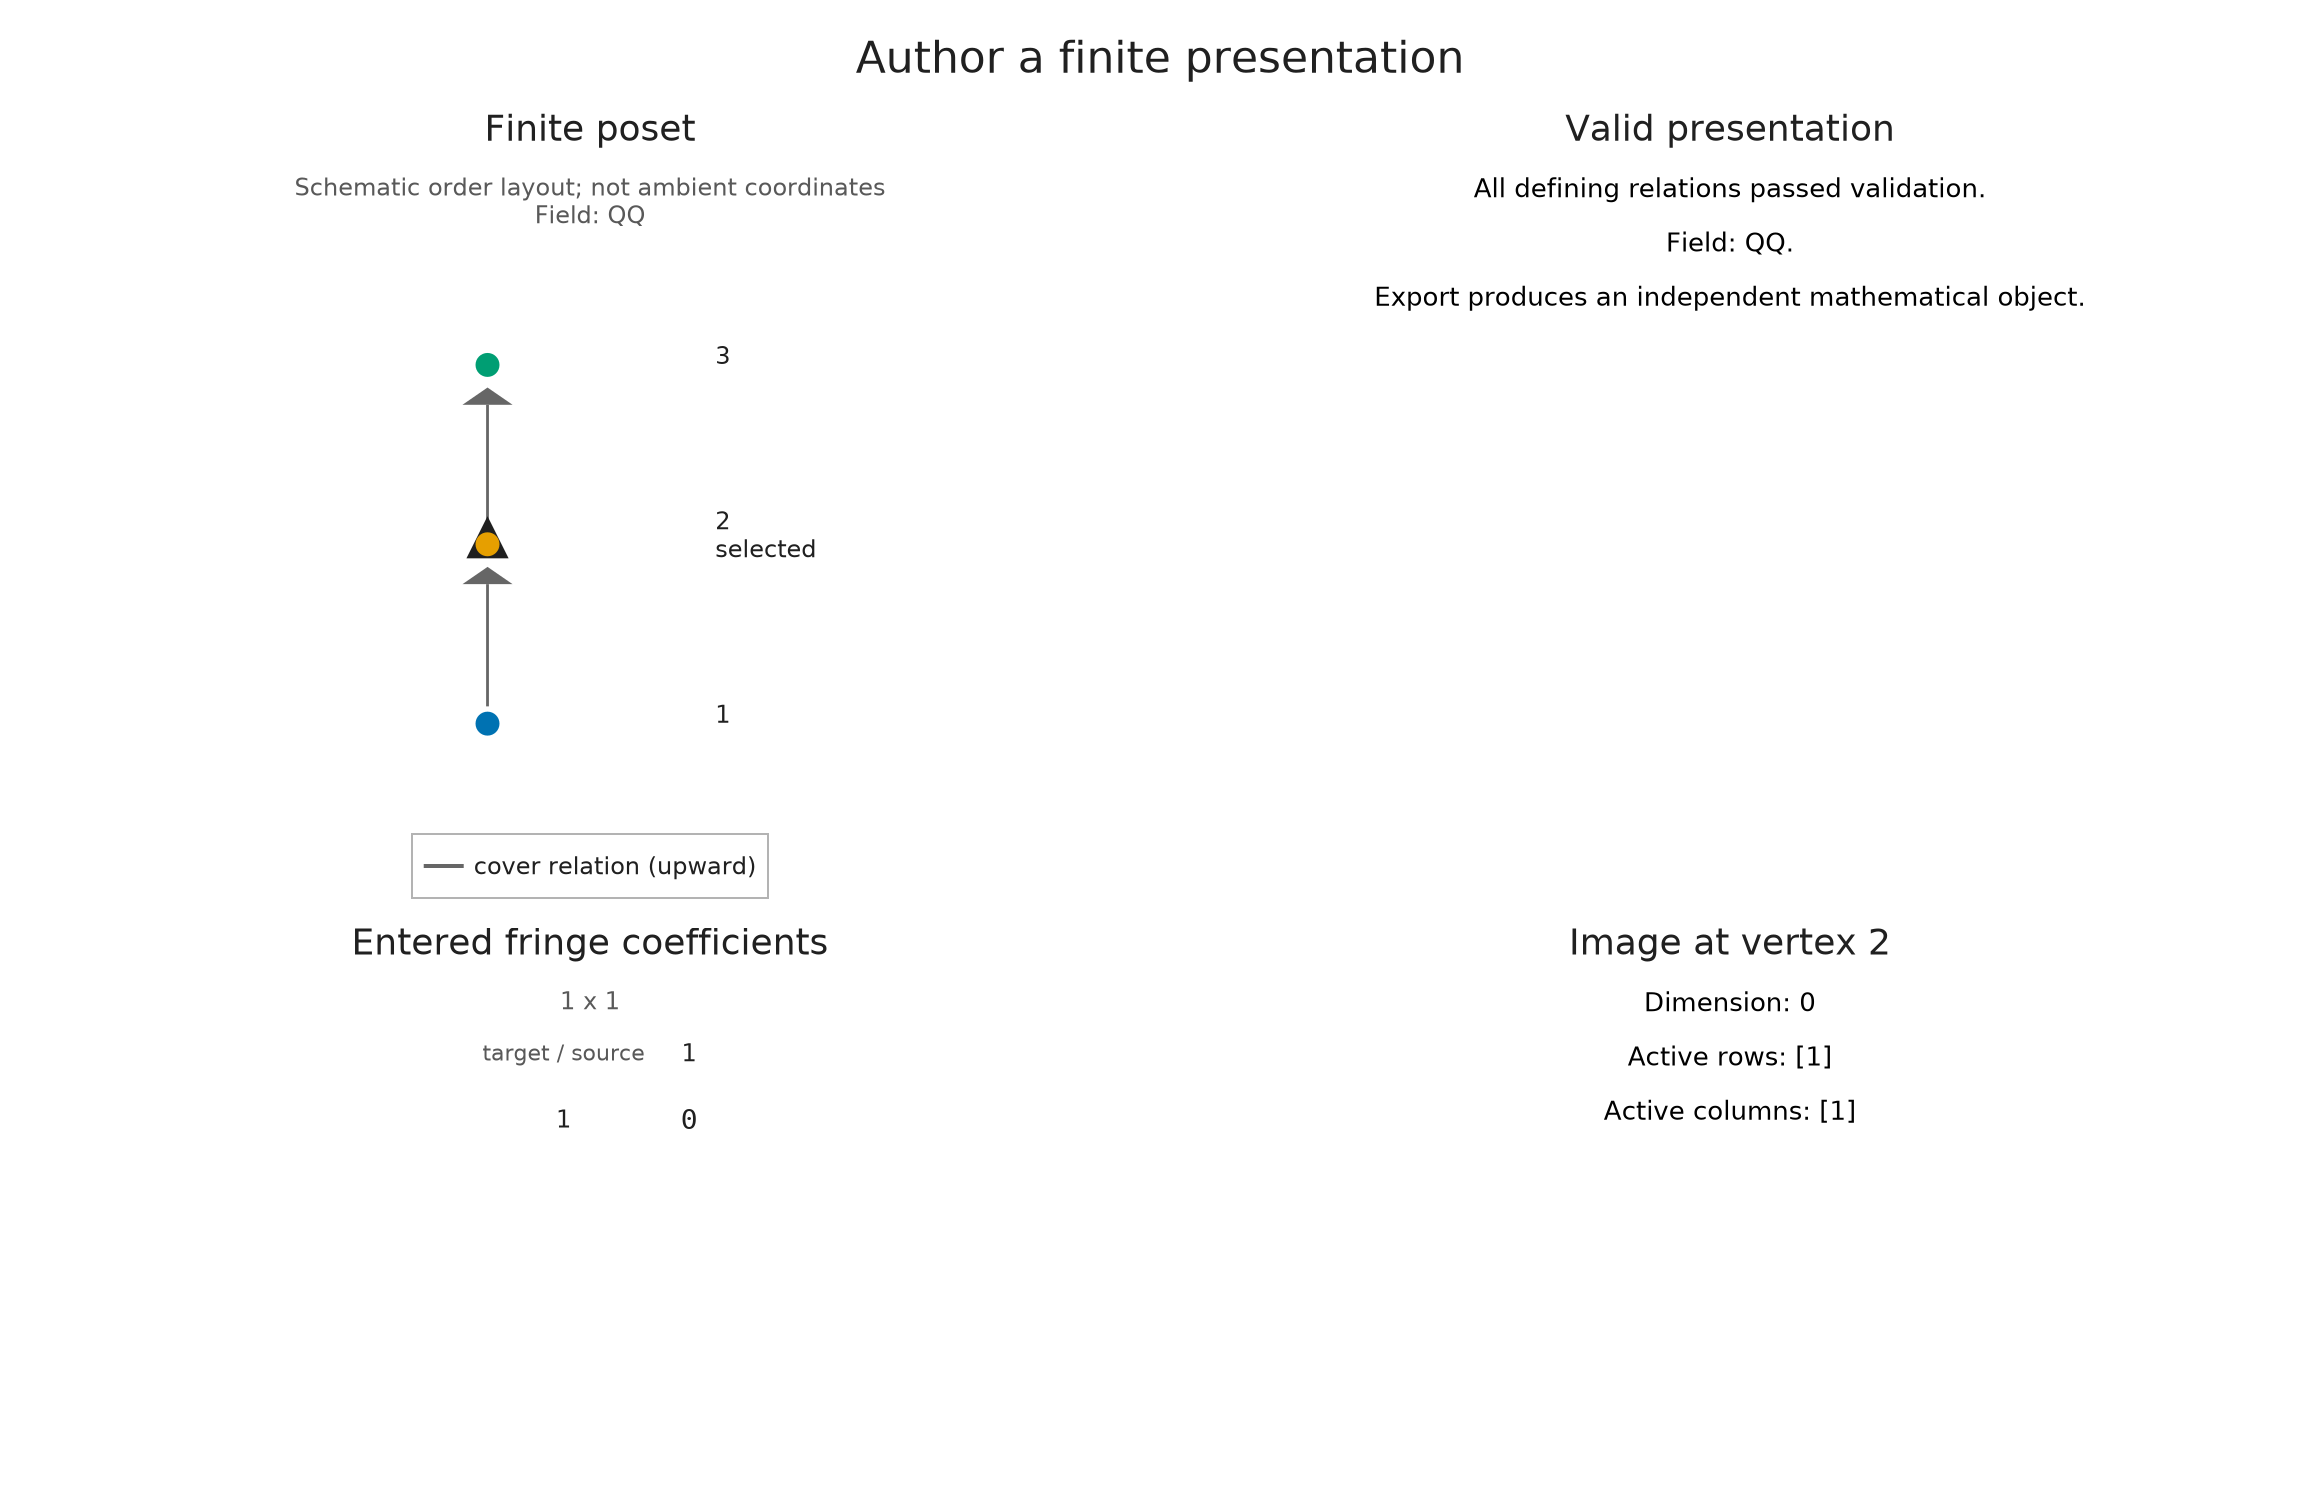

In [12]:
OP.edit_module!(presentation; matrix=[0;;])
@assert OP.dimensions(OP.editor_object(presentation)).fibers == [0, 0, 0]
OP.visualize(A.inspection_snapshot(presentation))

## Save or share the construction

A saved editor view keeps the declarative draft and its validation explanation. Reopening starts fresh validation and an empty undo history. Generated Julia code instead reconstructs a validated ordinary object; it is not evaluated while loading a saved view.

In [13]:
folder = mktempdir()
json_path = joinpath(folder, "diamond.json")
html_path = joinpath(folder, "diamond.html")
OP.save_visual_session(json_path, editor; caption="A checked diamond with a two-dimensional terminal stalk.")
OP.save_visual_session(html_path, editor; caption="A checked diamond with a two-dimensional terminal stalk.")
A.close_inspection!(editor)
reopened = OP.module_editor(OP.load_visual_session(json_path))
@assert A.check_module_editor(reopened).valid
@assert A.inspection_summary(reopened).undo_count == 0
OP.describe(reopened)

(kind = :module_editor, valid = true, input_kind = :module, field = TamerOp.CoreModules.CoeffFields.QQField(), selection = (vertex = 4, edge = (3, 4), revision = 1), revision = 1, closed = false, updating = false, undo_count = 0, redo_count = 0, history_limit = 32, listener_count = 0, listener_errors = (), limits = (max_vertices = 32, max_dimension = 32, max_entries = 20000))

In [14]:
code_path = joinpath(folder, "diamond.jl")
write(code_path, OP.editor_code(reopened))
@assert isfile(code_path)
A.close_inspection!(reopened)
A.close_inspection!(presentation)
(json=json_path, html=html_path, julia=code_path)

(json = "/tmp/jl_3yUJv4/diamond.json", html = "/tmp/jl_3yUJv4/diamond.html", julia = "/tmp/jl_3yUJv4/diamond.jl")

The finite diagram now defines one checked module, and the presentation example shows another algebraic input route. The [short construction recipe](../recipes/build_module.md) is useful when you only need the procedure. The [session implementation account](../implementation/inspection_sessions.md#keep-a-draft-distinct-from-a-mathematical-object) explains validation, failed-path witnesses and edit history.